In [2]:
from collections import OrderedDict
from typing import Tuple, Union

import numpy as np
import torch
import torch.nn.functional as F
from torch import nn


class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, inplanes, planes, stride=1):
        super().__init__()

        # all conv layers have stride 1. an avgpool is performed after the second convolution when stride > 1
        self.conv1 = nn.Conv2d(inplanes, planes, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)

        self.conv2 = nn.Conv2d(planes, planes, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.avgpool = nn.AvgPool2d(stride) if stride > 1 else nn.Identity()

        self.conv3 = nn.Conv2d(planes, planes * self.expansion, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes * self.expansion)

        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        self.stride = stride

        if stride > 1 or inplanes != planes * Bottleneck.expansion:
            # downsampling layer is prepended with an avgpool, and the subsequent convolution has stride 1
            self.downsample = nn.Sequential(OrderedDict([
                ("-1", nn.AvgPool2d(stride)),
                ("0", nn.Conv2d(inplanes, planes * self.expansion, 1, stride=1, bias=False)),
                ("1", nn.BatchNorm2d(planes * self.expansion))
            ]))

    def forward(self, x: torch.Tensor):
        identity = x

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.avgpool(out)
        out = self.bn3(self.conv3(out))

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)
        return out


class AttentionPool2d(nn.Module):
    def __init__(self, spacial_dim: int, embed_dim: int, num_heads: int, output_dim: int = None):
        super().__init__()
        self.positional_embedding = nn.Parameter(torch.randn(spacial_dim ** 2 + 1, embed_dim) / embed_dim ** 0.5)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.c_proj = nn.Linear(embed_dim, output_dim or embed_dim)
        self.num_heads = num_heads

    def forward(self, x):
        x = x.reshape(x.shape[0], x.shape[1], x.shape[2] * x.shape[3]).permute(2, 0, 1)  # NCHW -> (HW)NC
        x = torch.cat([x.mean(dim=0, keepdim=True), x], dim=0)  # (HW+1)NC
        x = x + self.positional_embedding[:, None, :].to(x.dtype)  # (HW+1)NC
        x, _ = F.multi_head_attention_forward(
            query=x, key=x, value=x,
            embed_dim_to_check=x.shape[-1],
            num_heads=self.num_heads,
            q_proj_weight=self.q_proj.weight,
            k_proj_weight=self.k_proj.weight,
            v_proj_weight=self.v_proj.weight,
            in_proj_weight=None,
            in_proj_bias=torch.cat([self.q_proj.bias, self.k_proj.bias, self.v_proj.bias]),
            bias_k=None,
            bias_v=None,
            add_zero_attn=False,
            dropout_p=0,
            out_proj_weight=self.c_proj.weight,
            out_proj_bias=self.c_proj.bias,
            use_separate_proj_weight=True,
            training=self.training,
            need_weights=False
        )

        return x[0]


class ModifiedResNet(nn.Module):
    """
    A ResNet class that is similar to torchvision's but contains the following changes:
    - There are now 3 "stem" convolutions as opposed to 1, with an average pool instead of a max pool.
    - Performs anti-aliasing strided convolutions, where an avgpool is prepended to convolutions with stride > 1
    - The final pooling layer is a QKV attention instead of an average pool
    """

    def __init__(self, layers, output_dim, heads, input_resolution=224, width=64):
        super().__init__()
        self.output_dim = output_dim
        self.input_resolution = input_resolution

        # the 3-layer stem
        self.conv1 = nn.Conv2d(3, width // 2, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(width // 2)
        self.conv2 = nn.Conv2d(width // 2, width // 2, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(width // 2)
        self.conv3 = nn.Conv2d(width // 2, width, kernel_size=3, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(width)
        self.avgpool = nn.AvgPool2d(2)
        self.relu = nn.ReLU(inplace=True)

        # residual layers
        self._inplanes = width  # this is a *mutable* variable used during construction
        self.layer1 = self._make_layer(width, layers[0])
        self.layer2 = self._make_layer(width * 2, layers[1], stride=2)
        self.layer3 = self._make_layer(width * 4, layers[2], stride=2)
        self.layer4 = self._make_layer(width * 8, layers[3], stride=2)

        embed_dim = width * 32  # the ResNet feature dimension
        self.attnpool = AttentionPool2d(input_resolution // 32, embed_dim, heads, output_dim)

    def _make_layer(self, planes, blocks, stride=1):
        layers = [Bottleneck(self._inplanes, planes, stride)]

        self._inplanes = planes * Bottleneck.expansion
        for _ in range(1, blocks):
            layers.append(Bottleneck(self._inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        def stem(x):
            for conv, bn in [(self.conv1, self.bn1), (self.conv2, self.bn2), (self.conv3, self.bn3)]:
                x = self.relu(bn(conv(x)))
            x = self.avgpool(x)
            return x

        x = x.type(self.conv1.weight.dtype)
        x = stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.attnpool(x)

        return x


class LayerNorm(nn.LayerNorm):
    """Subclass torch's LayerNorm to handle fp16."""

    def forward(self, x: torch.Tensor):
        orig_type = x.dtype
        ret = super().forward(x.type(torch.float32))
        return ret.type(orig_type)


class QuickGELU(nn.Module):
    def forward(self, x: torch.Tensor):
        return x * torch.sigmoid(1.702 * x)


class ResidualAttentionBlock(nn.Module):
    def __init__(self, d_model: int, n_head: int, attn_mask: torch.Tensor = None):
        super().__init__()

        self.attn = nn.MultiheadAttention(d_model, n_head)
        self.ln_1 = LayerNorm(d_model)
        self.mlp = nn.Sequential(OrderedDict([
            ("c_fc", nn.Linear(d_model, d_model * 4)),
            ("gelu", QuickGELU()),
            ("c_proj", nn.Linear(d_model * 4, d_model))
        ]))
        self.ln_2 = LayerNorm(d_model)
        self.attn_mask = attn_mask

    def attention(self, x: torch.Tensor):
        self.attn_mask = self.attn_mask.to(dtype=x.dtype, device=x.device) if self.attn_mask is not None else None
        return self.attn(x, x, x, need_weights=False, attn_mask=self.attn_mask)[0]

    def forward(self, x: torch.Tensor):
        x = x + self.attention(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


class ResidualAttentionBlock_IVLP(nn.Module):
    def __init__(self, d_model: int, n_head: int, attn_mask: torch.Tensor = None, add_prompt=False,
                 text_layer=False, i=0, design_details=None):
        super().__init__()

        self.attn = nn.MultiheadAttention(d_model, n_head)
        self.ln_1 = LayerNorm(d_model)
        self.mlp = nn.Sequential(OrderedDict([
            ("c_fc", nn.Linear(d_model, d_model * 4)),
            ("gelu", QuickGELU()),
            ("c_proj", nn.Linear(d_model * 4, d_model))
        ]))
        self.ln_2 = LayerNorm(d_model)
        # Only add learnable tokens if flag is set True
        # For the first iteration i, we should not add the learnable parameters
        # as it is already been taken care of in the very start, for both text
        # and the visual branch
        self.text_layer = text_layer
        self.attn_mask = attn_mask
        if i != 0:
            self.add_prompt = add_prompt
            if self.add_prompt:
                if self.text_layer:
                    self.n_ctx_text = design_details["language_ctx"]  # hyperparameter
                    ctx_vectors = torch.empty(self.n_ctx_text, d_model)
                else:
                    self.n_ctx_visual = design_details["vision_ctx"]  # hyperparameter
                    ctx_vectors = torch.empty(self.n_ctx_visual, d_model)
                # Code snippet for per layer visual prompts
                nn.init.normal_(ctx_vectors, std=0.02)
                self.VPT_shallow = nn.Parameter(ctx_vectors)
        else:
            self.add_prompt = False

    def attention(self, x: torch.Tensor):
        self.attn_mask = self.attn_mask.to(dtype=x.dtype, device=x.device) if self.attn_mask is not None else None
        return self.attn(x, x, x, need_weights=False, attn_mask=self.attn_mask)[0]

    def forward(self, x: torch.Tensor):
        # Will need to append the learnable tokens for this layer here
        # Check if flag was set for this layer or not
        if self.add_prompt:
            # Also see if this is textual transformer layer or not
            if not self.text_layer:
                # Remove the outputs produced by learnable tokens of previous layer
                prefix = x[0:x.shape[0] - self.n_ctx_visual, :, :]
                # Create/configure learnable tokens of this layer
                visual_context = self.VPT_shallow.expand(x.shape[1], -1, -1).permute(1, 0, 2).half()
                # Add the learnable tokens of this layer with the input, by replacing the previous
                # layer learnable tokens
                x = torch.cat([prefix, visual_context], dim=0)
            else:
                # Appending the learnable tokens in different way
                # x -> [77, NCLS, DIM]
                # First remove the learnable tokens from previous layer
                prefix = x[:1, :, :]
                suffix = x[1 + self.n_ctx_text:, :, :]
                # Create/configure learnable tokens of this layer
                textual_context = self.VPT_shallow.expand(x.shape[1], -1, -1).permute(1, 0, 2).half()
                # Add the learnable tokens of this layer with the input, replaced by previous
                # layer learnable tokens
                x = torch.cat([prefix, textual_context, suffix], dim=0)

        x = x + self.attention(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


class ResidualAttentionBlock_MaPLe(nn.Module):
    def __init__(self, d_model: int, n_head: int, attn_mask: torch.Tensor = None, design_details=None,
                 text_layer=False, i=0):
        super().__init__()

        self.attn = nn.MultiheadAttention(d_model, n_head)
        self.ln_1 = LayerNorm(d_model)
        self.mlp = nn.Sequential(OrderedDict([
            ("c_fc", nn.Linear(d_model, d_model * 4)),
            ("gelu", QuickGELU()),
            ("c_proj", nn.Linear(d_model * 4, d_model))
        ]))
        self.ln_2 = LayerNorm(d_model)
        self.text_layer = text_layer
        self.attn_mask = attn_mask
        self.compound_prompt_nctx = design_details['maple_length']
        if i == 0:
            self.first_layer = True
        else:
            self.first_layer = False

    def attention(self, x: torch.Tensor):
        # Dynamically adjust attention mask based on actual sequence length
        if self.attn_mask is not None:
            attn_mask = self.attn_mask.to(dtype=x.dtype, device=x.device)
            # If sequence length doesn't match mask size, create a new mask
            if attn_mask.shape[0] != x.shape[0]:
                seq_len = x.shape[0]
                attn_mask = torch.empty(seq_len, seq_len, dtype=x.dtype, device=x.device)
                attn_mask.fill_(float("-inf"))
                attn_mask.triu_(1)  # Causal mask
        else:
            attn_mask = None
            
        return self.attn(x, x, x, need_weights=False, attn_mask=attn_mask)[0]

    def forward(self, inputs):
        x = inputs[0]
        compound_prompts_deeper = inputs[1]
        counter = inputs[2]
        if not self.first_layer:
            if len(compound_prompts_deeper) > 0:
                if not self.text_layer:
                    if not (counter > len(compound_prompts_deeper) - 1):
                        prefix = x[0:x.shape[0] - self.compound_prompt_nctx, :, :]
                        visual_context = compound_prompts_deeper[counter]
                        visual_context = visual_context.expand(x.shape[1], -1, -1).permute(1, 0, 2).half()
                        x = torch.cat([prefix, visual_context], dim=0)
                        counter += 1
                else:
                    if not (counter > len(compound_prompts_deeper) - 1):
                        prefix = x[:1, :, :]
                        suffix = x[1 + self.compound_prompt_nctx:, :, :]
                        textual_context = compound_prompts_deeper[counter]
                        textual_context = textual_context.expand(x.shape[1], -1, -1).permute(1, 0, 2).half()
                        x = torch.cat([prefix, textual_context, suffix], dim=0)
                        counter += 1
        x = x + self.attention(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return [x, compound_prompts_deeper, counter]


class Transformer(nn.Module):
    def __init__(self, width: int, layers: int, heads: int, attn_mask: torch.Tensor = None, prompts_needed=0,
                 text_layer=False, design_details=None):
        super().__init__()
        self.width = width
        self.layers = layers
        # Implements respective encoder blocks for a given design choice
        current_trainer = design_details['trainer']
        if current_trainer == 'IVLP' or current_trainer == 'VPT':
            self.resblocks = nn.Sequential(*[ResidualAttentionBlock_IVLP(width, heads, attn_mask, True,
                                                                         text_layer, i,
                                                                         design_details) if prompts_needed > i
                                             else ResidualAttentionBlock_IVLP(width, heads, attn_mask, False,
                                                                              text_layer, i, design_details)
                                             for i in range(layers)])
        elif current_trainer == 'MaPLe':
            self.resblocks = nn.Sequential(
                *[ResidualAttentionBlock_MaPLe(width, heads, attn_mask, design_details, text_layer, i)
                  for i in range(layers)])
        else:
            # Corresponds to default CoOp or CoCoOp
            assert current_trainer == 'CoOp' or current_trainer == 'CoCoOp'
            self.resblocks = nn.Sequential(*[ResidualAttentionBlock(width, heads, attn_mask) for _ in range(layers)])

    def forward(self, x: torch.Tensor):
        return self.resblocks(x)


class VisionTransformer(nn.Module):
    def __init__(self, input_resolution: int, patch_size: int, width: int, layers: int, heads: int,
                 output_dim: int, design_details):
        super().__init__()
        self.input_resolution = input_resolution
        self.output_dim = output_dim
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=width, kernel_size=patch_size, stride=patch_size, bias=False)
        if design_details["vision_depth"] == 0:
            self.VPT_shallow = False
        else:
            self.VPT_shallow = True
        if self.VPT_shallow:
            # Add visual prompt tokens here
            n_ctx = design_details["vision_ctx"]  # hyperparameter
            ctx_vectors = torch.empty(n_ctx, width)
            nn.init.normal_(ctx_vectors, std=0.02)
            self.VPT = nn.Parameter(ctx_vectors)
            # self.VPT.half()
        scale = width ** -0.5
        self.class_embedding = nn.Parameter(scale * torch.randn(width))
        self.positional_embedding = nn.Parameter(scale * torch.randn((input_resolution // patch_size) ** 2 + 1, width))
        self.ln_pre = LayerNorm(width)
        # hyper-parameter if need to add prompt embeddings inside to the input
        # of transformer block or not:
        self.prompt_till_layer_visual = design_details["vision_depth"]
        self.transformer = Transformer(width, layers, heads, prompts_needed=self.prompt_till_layer_visual,
                                       design_details=design_details)

        self.ln_post = LayerNorm(width)
        self.proj = nn.Parameter(scale * torch.randn(width, output_dim))

    def forward(self, x: torch.Tensor):
        x = self.conv1(x)  # shape = [*, width, grid, grid]
        x = x.reshape(x.shape[0], x.shape[1], -1)  # shape = [*, width, grid ** 2]
        x = x.permute(0, 2, 1)  # shape = [*, grid ** 2, width]
        x = torch.cat(
            [self.class_embedding.to(x.dtype) + torch.zeros(x.shape[0], 1, x.shape[-1], dtype=x.dtype, device=x.device),
             x], dim=1)  # shape = [*, grid ** 2 + 1, width]
        x = x + self.positional_embedding.to(x.dtype)

        # After positional embeddings, we will attach prompts with the model, remember only those
        # are trainable parameters here in whole image encoder.
        if self.VPT_shallow:
            visual_ctx = self.VPT.expand(x.shape[0], -1, -1).half()
            x = torch.cat([x, visual_ctx], dim=1)
        else:
            assert self.prompt_till_layer_visual == 0

        # Normal code as before
        x = self.ln_pre(x)

        x = x.permute(1, 0, 2)  # NLD -> LND
        x = self.transformer(x)
        x = x.permute(1, 0, 2)  # LND -> NLD

        x = self.ln_post(x[:, 0, :])

        if self.proj is not None:
            x = x @ self.proj

        return x


class VisionTransformer_MaPLe(nn.Module):
    def __init__(self, input_resolution: int, patch_size: int, width: int, layers: int, heads: int, output_dim: int,
                 design_details):
        super().__init__()
        self.input_resolution = input_resolution
        self.output_dim = output_dim
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=width, kernel_size=patch_size, stride=patch_size, bias=False)
        self.VPT_shallow = True
        scale = width ** -0.5
        self.class_embedding = nn.Parameter(scale * torch.randn(width))
        self.positional_embedding = nn.Parameter(scale * torch.randn((input_resolution // patch_size) ** 2 + 1, width))
        self.ln_pre = LayerNorm(width)
        # hyper-parameter if need to add prompt embeddings inside to the input
        # of transformer block or not:
        self.prompt_till_layer_visual = 0
        self.transformer = Transformer(width, layers, heads, design_details=design_details)

        self.ln_post = LayerNorm(width)
        self.proj = nn.Parameter(scale * torch.randn(width, output_dim))

    def forward(self, x: torch.Tensor, shared_ctx, compound_deeper_prompts):
        x = self.conv1(x)  # shape = [*, width, grid, grid]
        x = x.reshape(x.shape[0], x.shape[1], -1)  # shape = [*, width, grid ** 2]
        x = x.permute(0, 2, 1)  # shape = [*, grid ** 2, width]
        x = torch.cat(
            [self.class_embedding.to(x.dtype) + torch.zeros(x.shape[0], 1, x.shape[-1], dtype=x.dtype, device=x.device),
             x], dim=1)  # shape = [*, grid ** 2 + 1, width]
        x = x + self.positional_embedding.to(x.dtype)

        # After positional embeddings, we will attach prompts with the model, remember only those
        # are trainable parameters here in whole image encoder.
        if self.VPT_shallow:
            visual_ctx = shared_ctx.expand(x.shape[0], -1, -1).half()
            x = torch.cat([x, visual_ctx], dim=1)
        else:
            assert self.prompt_till_layer_visual == 0

        # Normal code as before
        x = self.ln_pre(x)

        x = x.permute(1, 0, 2)  # NLD -> LND
        # Again combine the inputs, so nn.sequential can work
        outputs = self.transformer([x, compound_deeper_prompts, 0])  # third argument is counter
        x = outputs[0]
        x = x.permute(1, 0, 2)  # LND -> NLD

        x = self.ln_post(x[:, 0, :])

        if self.proj is not None:
            x = x @ self.proj

        return x


class CLIP(nn.Module):
    def __init__(self,
                 embed_dim: int,
                 # vision
                 image_resolution: int,
                 vision_layers: Union[Tuple[int, int, int, int], int],
                 vision_width: int,
                 vision_patch_size: int,
                 # text
                 context_length: int,
                 vocab_size: int,
                 transformer_width: int,
                 transformer_heads: int,
                 transformer_layers: int,
                 design_details
                 ):
        super().__init__()

        self.context_length = context_length
        trainer = design_details['trainer']

        if isinstance(vision_layers, (tuple, list)):
            vision_heads = vision_width * 32 // 64
            self.visual = ModifiedResNet(
                layers=vision_layers,
                output_dim=embed_dim,
                heads=vision_heads,
                input_resolution=image_resolution,
                width=vision_width
            )
        else:
            vision_heads = vision_width // 64
            if trainer == "MaPLe":
                self.visual = VisionTransformer_MaPLe(
                    input_resolution=image_resolution,
                    patch_size=vision_patch_size,
                    width=vision_width,
                    layers=vision_layers,
                    heads=vision_heads,
                    output_dim=embed_dim,
                    design_details=design_details
                )
            else:
                self.visual = VisionTransformer(
                    input_resolution=image_resolution,
                    patch_size=vision_patch_size,
                    width=vision_width,
                    layers=vision_layers,
                    heads=vision_heads,
                    output_dim=embed_dim,
                    design_details=design_details
                )
        # hyper-parameter if need to add prompt embeddings inside to the input
        # of transformer block or not:
        prompt_till_layer_text = design_details['language_depth']
        self.transformer = Transformer(
            width=transformer_width,
            layers=transformer_layers,
            heads=transformer_heads,
            attn_mask=self.build_attention_mask(),
            prompts_needed=prompt_till_layer_text,
            text_layer=True,
            design_details=design_details
        )

        self.vocab_size = vocab_size
        self.token_embedding = nn.Embedding(vocab_size, transformer_width)
        self.positional_embedding = nn.Parameter(torch.empty(self.context_length, transformer_width))
        self.ln_final = LayerNorm(transformer_width)

        self.text_projection = nn.Parameter(torch.empty(transformer_width, embed_dim))
        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1 / 0.07))

        self.initialize_parameters()

    def initialize_parameters(self):
        nn.init.normal_(self.token_embedding.weight, std=0.02)
        nn.init.normal_(self.positional_embedding, std=0.01)

        if isinstance(self.visual, ModifiedResNet):
            if self.visual.attnpool is not None:
                std = self.visual.attnpool.c_proj.in_features ** -0.5
                nn.init.normal_(self.visual.attnpool.q_proj.weight, std=std)
                nn.init.normal_(self.visual.attnpool.k_proj.weight, std=std)
                nn.init.normal_(self.visual.attnpool.v_proj.weight, std=std)
                nn.init.normal_(self.visual.attnpool.c_proj.weight, std=std)

            for resnet_block in [self.visual.layer1, self.visual.layer2, self.visual.layer3, self.visual.layer4]:
                for name, param in resnet_block.named_parameters():
                    if name.endswith("bn3.weight"):
                        nn.init.zeros_(param)

        proj_std = (self.transformer.width ** -0.5) * ((2 * self.transformer.layers) ** -0.5)
        attn_std = self.transformer.width ** -0.5
        fc_std = (2 * self.transformer.width) ** -0.5
        for block in self.transformer.resblocks:
            nn.init.normal_(block.attn.in_proj_weight, std=attn_std)
            nn.init.normal_(block.attn.out_proj.weight, std=proj_std)
            nn.init.normal_(block.mlp.c_fc.weight, std=fc_std)
            nn.init.normal_(block.mlp.c_proj.weight, std=proj_std)

        if self.text_projection is not None:
            nn.init.normal_(self.text_projection, std=self.transformer.width ** -0.5)

    def build_attention_mask(self):
        # lazily create causal attention mask, with full attention between the vision tokens
        # pytorch uses additive attention mask; fill with -inf
        mask = torch.empty(self.context_length, self.context_length)
        mask.fill_(float("-inf"))
        mask.triu_(1)  # zero out the lower diagonal
        return mask

    @property
    def dtype(self):
        return self.visual.conv1.weight.dtype

    def encode_image(self, image):
        return self.visual(image.type(self.dtype))

    def encode_text(self, text):
        x = self.token_embedding(text).type(self.dtype)  # [batch_size, n_ctx, d_model]

        x = x + self.positional_embedding.type(self.dtype)
        x = x.permute(1, 0, 2)  # NLD -> LND
        x = self.transformer(x)
        x = x.permute(1, 0, 2)  # LND -> NLD
        x = self.ln_final(x).type(self.dtype)

        # x.shape = [batch_size, n_ctx, transformer.width]
        # take features from the eot embedding (eot_token is the highest number in each sequence)
        x = x[torch.arange(x.shape[0]), text.argmax(dim=-1)] @ self.text_projection

        return x

    def forward(self, image, text):
        image_features = self.encode_image(image)
        text_features = self.encode_text(text)

        # normalized features
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

        # cosine similarity as logits
        logit_scale = self.logit_scale.exp()
        logits_per_image = logit_scale * image_features @ text_features.t()
        logits_per_text = logit_scale * text_features @ image_features.t()

        # shape = [global_batch_size, global_batch_size]
        return logits_per_image, logits_per_text


def convert_weights(model: nn.Module):
    """Convert applicable model parameters to fp16"""

    def _convert_weights_to_fp16(l):
        if isinstance(l, (nn.Conv1d, nn.Conv2d, nn.Linear)):
            l.weight.data = l.weight.data.half()
            if l.bias is not None:
                l.bias.data = l.bias.data.half()

        if isinstance(l, nn.MultiheadAttention):
            for attr in [*[f"{s}_proj_weight" for s in ["in", "q", "k", "v"]], "in_proj_bias", "bias_k", "bias_v"]:
                tensor = getattr(l, attr)
                if tensor is not None:
                    tensor.data = tensor.data.half()

        for name in ["text_projection", "proj"]:
            if hasattr(l, name):
                attr = getattr(l, name)
                if attr is not None:
                    attr.data = attr.data.half()

    model.apply(_convert_weights_to_fp16)


def build_model(state_dict: dict, design_details):
    vit = "visual.proj" in state_dict

    if vit:
        vision_width = state_dict["visual.conv1.weight"].shape[0]
        vision_layers = len(
            [k for k in state_dict.keys() if k.startswith("visual.") and k.endswith(".attn.in_proj_weight")])
        vision_patch_size = state_dict["visual.conv1.weight"].shape[-1]
        grid_size = round((state_dict["visual.positional_embedding"].shape[0] - 1) ** 0.5)
        image_resolution = vision_patch_size * grid_size
    else:
        counts: list = [len(set(k.split(".")[2] for k in state_dict if k.startswith(f"visual.layer{b}"))) for b in
                        [1, 2, 3, 4]]
        vision_layers = tuple(counts)
        vision_width = state_dict["visual.layer1.0.conv1.weight"].shape[0]
        output_width = round((state_dict["visual.attnpool.positional_embedding"].shape[0] - 1) ** 0.5)
        vision_patch_size = None
        assert output_width ** 2 + 1 == state_dict["visual.attnpool.positional_embedding"].shape[0]
        image_resolution = output_width * 32

    embed_dim = state_dict["text_projection"].shape[1]
    context_length = state_dict["positional_embedding"].shape[0]
    vocab_size = state_dict["token_embedding.weight"].shape[0]
    transformer_width = state_dict["ln_final.weight"].shape[0]
    transformer_heads = transformer_width // 64
    transformer_layers = len(set(k.split(".")[2] for k in state_dict if k.startswith(f"transformer.resblocks")))

    model = CLIP(
        embed_dim,
        image_resolution, vision_layers, vision_width, vision_patch_size,
        context_length, vocab_size, transformer_width, transformer_heads, transformer_layers, design_details
    )

    for key in ["input_resolution", "context_length", "vocab_size"]:
        if key in state_dict:
            del state_dict[key]

    convert_weights(model)
    try:
        model.load_state_dict(state_dict)
    except:
        missing_keys, _ = model.load_state_dict(state_dict, strict=False)
        print('Weights not found for some missing keys: ', missing_keys)
    return model.eval()

In [4]:
!pip install ftfy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 964.0 kB/s eta 0:00:000:00:01


In [5]:
import gzip
import html
import os
from functools import lru_cache

import ftfy
import regex as re


@lru_cache()
def default_bpe():
    # Use the Kaggle input path directly
    return "/kaggle/input/simple-vocab/bpe_simple_vocab_16e6.txt"

@lru_cache()
def bytes_to_unicode():
    """
    Returns list of utf-8 byte and a corresponding list of unicode strings.
    The reversible bpe codes work on unicode strings.
    This means you need a large # of unicode characters in your vocab if you want to avoid UNKs.
    When you're at something like a 10B token dataset you end up needing around 5K for decent coverage.
    This is a signficant percentage of your normal, say, 32K bpe vocab.
    To avoid that, we want lookup tables between utf-8 bytes and unicode strings.
    And avoids mapping to whitespace/control characters the bpe code barfs on.
    """
    bs = list(range(ord("!"), ord("~")+1))+list(range(ord("¡"), ord("¬")+1))+list(range(ord("®"), ord("ÿ")+1))
    cs = bs[:]
    n = 0
    for b in range(2**8):
        if b not in bs:
            bs.append(b)
            cs.append(2**8+n)
            n += 1
    cs = [chr(n) for n in cs]
    return dict(zip(bs, cs))


def get_pairs(word):
    """Return set of symbol pairs in a word.
    Word is represented as tuple of symbols (symbols being variable-length strings).
    """
    pairs = set()
    prev_char = word[0]
    for char in word[1:]:
        pairs.add((prev_char, char))
        prev_char = char
    return pairs


def basic_clean(text):
    text = ftfy.fix_text(text)
    text = html.unescape(html.unescape(text))
    return text.strip()


def whitespace_clean(text):
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    return text


class SimpleTokenizer(object):
    def __init__(self, bpe_path: str = default_bpe()):
        self.byte_encoder = bytes_to_unicode()
        self.byte_decoder = {v: k for k, v in self.byte_encoder.items()}
        with open(bpe_path, "r", encoding="utf-8") as f:
            merges = f.read().splitlines()
        merges = merges[1:49152-256-2+1]
        merges = [tuple(merge.split()) for merge in merges]
        vocab = list(bytes_to_unicode().values())
        vocab = vocab + [v+'</w>' for v in vocab]
        for merge in merges:
            vocab.append(''.join(merge))
        vocab.extend(['<|startoftext|>', '<|endoftext|>'])
        self.encoder = dict(zip(vocab, range(len(vocab))))
        self.decoder = {v: k for k, v in self.encoder.items()}
        self.bpe_ranks = dict(zip(merges, range(len(merges))))
        self.cache = {'<|startoftext|>': '<|startoftext|>', '<|endoftext|>': '<|endoftext|>'}
        self.pat = re.compile(r"""<\|startoftext\|>|<\|endoftext\|>|'s|'t|'re|'ve|'m|'ll|'d|[\p{L}]+|[\p{N}]|[^\s\p{L}\p{N}]+""", re.IGNORECASE)

    def bpe(self, token):
        if token in self.cache:
            return self.cache[token]
        word = tuple(token[:-1]) + ( token[-1] + '</w>',)
        pairs = get_pairs(word)

        if not pairs:
            return token+'</w>'

        while True:
            bigram = min(pairs, key = lambda pair: self.bpe_ranks.get(pair, float('inf')))
            if bigram not in self.bpe_ranks:
                break
            first, second = bigram
            new_word = []
            i = 0
            while i < len(word):
                try:
                    j = word.index(first, i)
                    new_word.extend(word[i:j])
                    i = j
                except:
                    new_word.extend(word[i:])
                    break

                if word[i] == first and i < len(word)-1 and word[i+1] == second:
                    new_word.append(first+second)
                    i += 2
                else:
                    new_word.append(word[i])
                    i += 1
            new_word = tuple(new_word)
            word = new_word
            if len(word) == 1:
                break
            else:
                pairs = get_pairs(word)
        word = ' '.join(word)
        self.cache[token] = word
        return word

    def encode(self, text):
        bpe_tokens = []
        text = whitespace_clean(basic_clean(text)).lower()
        for token in re.findall(self.pat, text):
            token = ''.join(self.byte_encoder[b] for b in token.encode('utf-8'))
            bpe_tokens.extend(self.encoder[bpe_token] for bpe_token in self.bpe(token).split(' '))
        return bpe_tokens

    def decode(self, tokens):
        text = ''.join([self.decoder[token] for token in tokens])
        text = bytearray([self.byte_decoder[c] for c in text]).decode('utf-8', errors="replace").replace('</w>', ' ')
        return text

In [6]:
import hashlib
import os
import urllib
import warnings
from typing import Union, List

import torch
from PIL import Image
from torchvision.transforms import Compose, Resize, CenterCrop, ToTensor, Normalize
from tqdm import tqdm

try:
    from torchvision.transforms import InterpolationMode
    BICUBIC = InterpolationMode.BICUBIC
except ImportError:
    BICUBIC = Image.BICUBIC


if torch.__version__.split(".") < ["1", "7", "1"]:
    warnings.warn("PyTorch version 1.7.1 or higher is recommended")


__all__ = ["available_models", "load", "tokenize"]
_Tokenizer = SimpleTokenizer
_tokenizer = _Tokenizer()  # this now works the same as before

_MODELS = {
    "RN50": "https://openaipublic.azureedge.net/clip/models/afeb0e10f9e5a86da6080e35cf09123aca3b358a0c3e3b6c78a7b63bc04b6762/RN50.pt",
    "RN101": "https://openaipublic.azureedge.net/clip/models/8fa8567bab74a42d41c5915025a8e4538c3bdbe8804a470a72f30b0d94fab599/RN101.pt",
    "RN50x4": "https://openaipublic.azureedge.net/clip/models/7e526bd135e493cef0776de27d5f42653e6b4c8bf9e0f653bb11773263205fdd/RN50x4.pt",
    "RN50x16": "https://openaipublic.azureedge.net/clip/models/52378b407f34354e150460fe41077663dd5b39c54cd0bfd2b27167a4a06ec9aa/RN50x16.pt",
    "ViT-B/32": "https://openaipublic.azureedge.net/clip/models/40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af/ViT-B-32.pt",
    "ViT-B/16": "https://openaipublic.azureedge.net/clip/models/5806e77cd80f8b59890b7e101eabd078d9fb84e6937f9e85e4ecb61988df416f/ViT-B-16.pt",
}


def _download(url: str, root: str = os.path.expanduser("~/.cache/clip")):
    os.makedirs(root, exist_ok=True)
    filename = os.path.basename(url)

    expected_sha256 = url.split("/")[-2]
    download_target = os.path.join(root, filename)

    if os.path.exists(download_target) and not os.path.isfile(download_target):
        raise RuntimeError(f"{download_target} exists and is not a regular file")

    if os.path.isfile(download_target):
        if hashlib.sha256(open(download_target, "rb").read()).hexdigest() == expected_sha256:
            return download_target
        else:
            warnings.warn(f"{download_target} exists, but the SHA256 checksum does not match; re-downloading the file")

    with urllib.request.urlopen(url) as source, open(download_target, "wb") as output:
        with tqdm(total=int(source.info().get("Content-Length")), ncols=80, unit='iB', unit_scale=True) as loop:
            while True:
                buffer = source.read(8192)
                if not buffer:
                    break

                output.write(buffer)
                loop.update(len(buffer))

    if hashlib.sha256(open(download_target, "rb").read()).hexdigest() != expected_sha256:
        raise RuntimeError(f"Model has been downloaded but the SHA256 checksum does not not match")

    return download_target


def _transform(n_px):
    return Compose([
        Resize(n_px, interpolation=BICUBIC),
        CenterCrop(n_px),
        lambda image: image.convert("RGB"),
        ToTensor(),
        Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)),
    ])


def available_models() -> List[str]:
    """Returns the names of available CLIP models"""
    return list(_MODELS.keys())


def load(name: str, device: Union[str, torch.device] = "cuda" if torch.cuda.is_available() else "cpu", jit=False):
    """Load a CLIP model

    Parameters
    ----------
    name : str
        A model name listed by `available_models()`, or the path to a model checkpoint containing the state_dict

    device : Union[str, torch.device]
        The device to put the loaded model

    jit : bool
        Whether to load the optimized JIT model or more hackable non-JIT model (default).

    Returns
    -------
    model : torch.nn.Module
        The CLIP model

    preprocess : Callable[[PIL.Image], torch.Tensor]
        A torchvision transform that converts a PIL image into a tensor that the returned model can take as its input
    """
    if name in _MODELS:
        model_path = _download(_MODELS[name])
    elif os.path.isfile(name):
        model_path = name
    else:
        raise RuntimeError(f"Model {name} not found; available models = {available_models()}")

    try:
        # loading JIT archive
        model = torch.jit.load(model_path, map_location=device if jit else "cpu").eval()
        state_dict = None
    except RuntimeError:
        # loading saved state dict
        if jit:
            warnings.warn(f"File {model_path} is not a JIT archive. Loading as a state dict instead")
            jit = False
        state_dict = torch.load(model_path, map_location="cpu")

    if not jit:
        
        model = build_model(state_dict or model.state_dict(),None).to(device)
        if str(device) == "cpu":
            model.float()
        return model, _transform(model.visual.input_resolution)

    # patch the device names
    device_holder = torch.jit.trace(lambda: torch.ones([]).to(torch.device(device)), example_inputs=[])
    device_node = [n for n in device_holder.graph.findAllNodes("prim::Constant") if "Device" in repr(n)][-1]

    def patch_device(module):
        try:
            graphs = [module.graph] if hasattr(module, "graph") else []
        except RuntimeError:
            graphs = []

        if hasattr(module, "forward1"):
            graphs.append(module.forward1.graph)

        for graph in graphs:
            for node in graph.findAllNodes("prim::Constant"):
                if "value" in node.attributeNames() and str(node["value"]).startswith("cuda"):
                    node.copyAttributes(device_node)

    model.apply(patch_device)
    patch_device(model.encode_image)
    patch_device(model.encode_text)

    # patch dtype to float32 on CPU
    if str(device) == "cpu":
        float_holder = torch.jit.trace(lambda: torch.ones([]).float(), example_inputs=[])
        float_input = list(float_holder.graph.findNode("aten::to").inputs())[1]
        float_node = float_input.node()

        def patch_float(module):
            try:
                graphs = [module.graph] if hasattr(module, "graph") else []
            except RuntimeError:
                graphs = []

            if hasattr(module, "forward1"):
                graphs.append(module.forward1.graph)

            for graph in graphs:
                for node in graph.findAllNodes("aten::to"):
                    inputs = list(node.inputs())
                    for i in [1, 2]:  # dtype can be the second or third argument to aten::to()
                        if inputs[i].node()["value"] == 5:
                            inputs[i].node().copyAttributes(float_node)

        model.apply(patch_float)
        patch_float(model.encode_image)
        patch_float(model.encode_text)

        model.float()

    return model, _transform(model.input_resolution.item())


def tokenize(texts: Union[str, List[str]], context_length: int = 77, truncate: bool = False) -> torch.LongTensor:
    """
    Returns the tokenized representation of given input string(s)

    Parameters
    ----------
    texts : Union[str, List[str]]
        An input string or a list of input strings to tokenize

    context_length : int
        The context length to use; all CLIP models use 77 as the context length

    truncate: bool
        Whether to truncate the text in case its encoding is longer than the context length

    Returns
    -------
    A two-dimensional tensor containing the resulting tokens, shape = [number of input strings, context_length]
    """
    if isinstance(texts, str):
        texts = [texts]

    sot_token = _tokenizer.encoder["<|startoftext|>"]
    eot_token = _tokenizer.encoder["<|endoftext|>"]
    all_tokens = [[sot_token] + _tokenizer.encode(text) + [eot_token] for text in texts]
    result = torch.zeros(len(all_tokens), context_length, dtype=torch.long)

    for i, tokens in enumerate(all_tokens):
        if len(tokens) > context_length:
            if truncate:
                tokens = tokens[:context_length]
                tokens[-1] = eot_token
            else:
                raise RuntimeError(f"Input {texts[i]} is too long for context length {context_length}")
        result[i, :len(tokens)] = torch.tensor(tokens)

    return result

Using device: cuda

Loading CLIP model...

Fine-grained Pacemaker Classification with MaPLe
Train samples: 1160
Val samples: 291
Test samples: 225

Number of classes: 45
Classes: ['BIO - Actros_Philos', 'BIO - Cyclos', 'BIO - Evia', 'BOS - Altrua_Insignia', 'BOS - Autogen_Teligen_Energen_Cognis', 'BOS - Contak Renewal 4', 'BOS - Contak Renewal TR2', 'BOS - ContakTR_Discovery_Meridian_Pulsar Max', 'BOS - Emblem', 'BOS - Ingenio']...

Building MaPLe model with class-specific prompts...
Initial context: "X X X X X X X X X X"
Number of MaPLe context words (tokens): 10
Number of classes: 45

Trainable parameters: 7,492,608

Starting training...

Epoch 1/50
--------------------------------------------------
Epoch [1] Batch [10/37] Loss: 4.5560
Epoch [1] Batch [20/37] Loss: 3.8893
Epoch [1] Batch [30/37] Loss: 4.1782
Train Loss: 4.6501, Train Acc: 0.0440
Val Top-1 Acc: 0.0344, Val Top-3 Acc: 0.0893
F1 Macro: 0.0030, F1 Weighted: 0.0033, AUC-ROC: 0.6640
✓ New best model! (Accuracy: 0.0344)

Ep

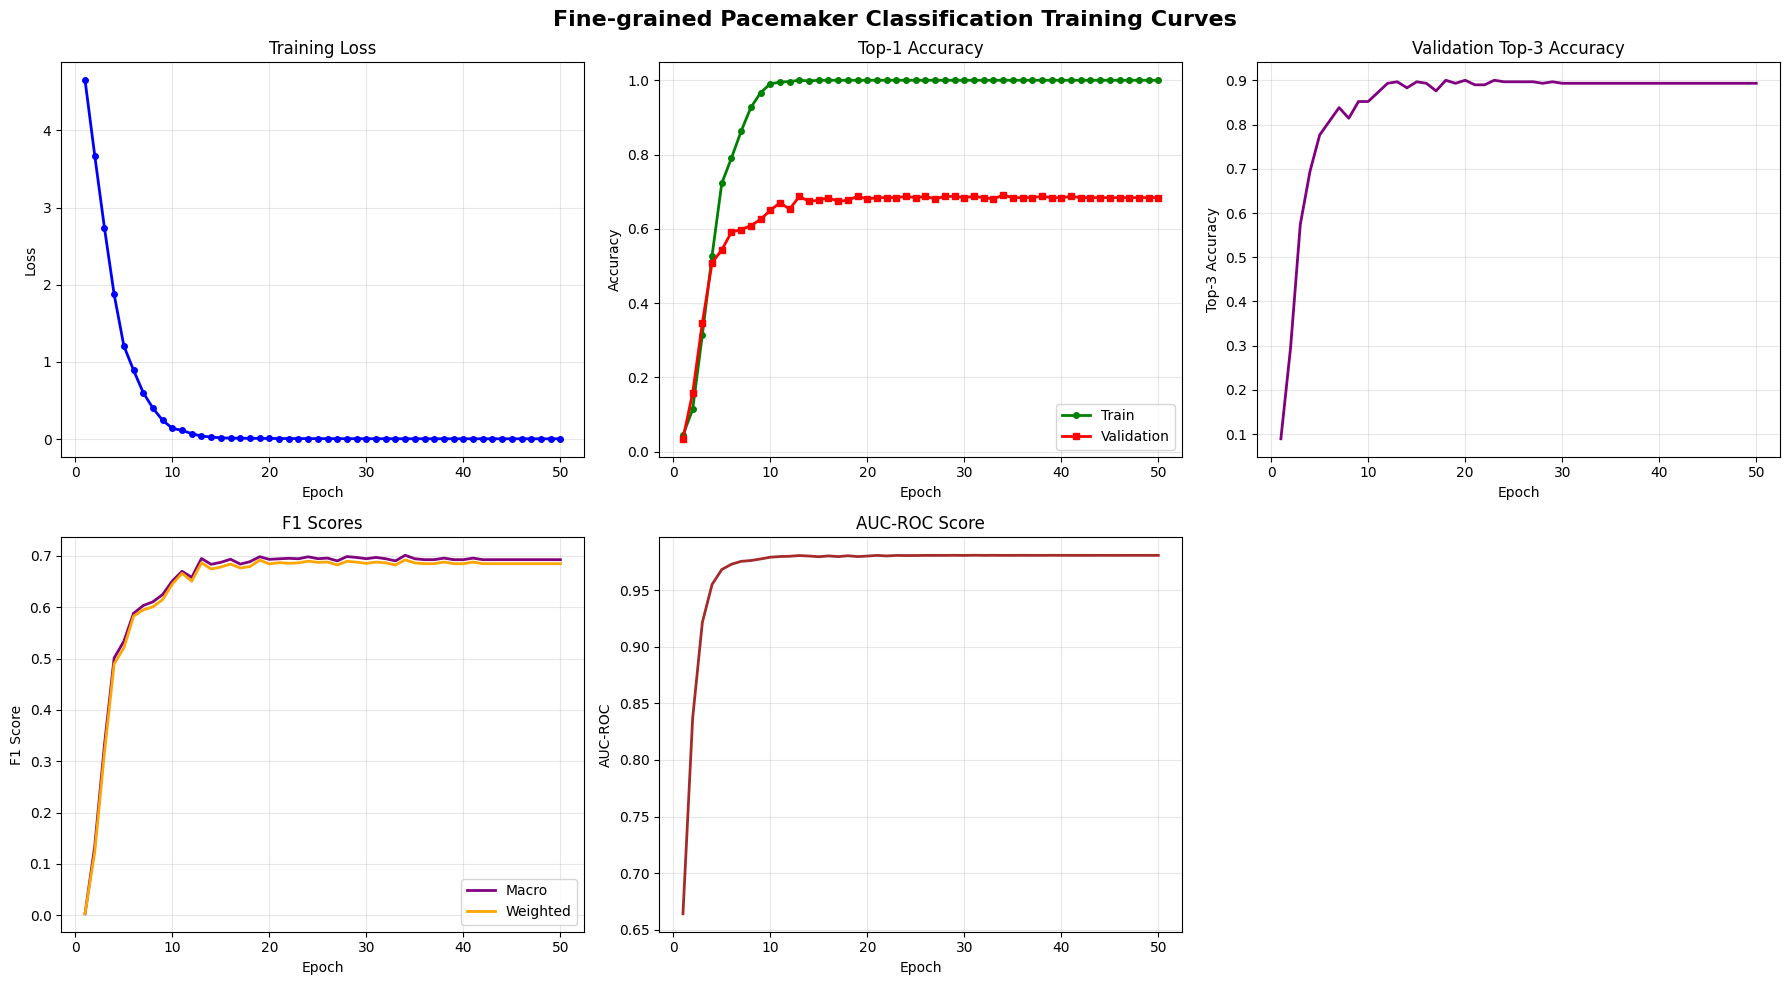


Final Test Evaluation

Test Results:
  Top-1 Accuracy: 0.7511
  Top-3 Accuracy: 0.9289
  F1-Score (Macro): 0.7488
  F1-Score (Weighted): 0.7488
  AUC-ROC: 0.9876


In [12]:
import os
import os.path as osp
from collections import OrderedDict
import math
import copy
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_auc_score, top_k_accuracy_score
import matplotlib.pyplot as plt

_Tokenizer = SimpleTokenizer
_tokenizer = _Tokenizer()

# ============== Configuration Class ==============
class Config:
    def __init__(self):
        self.MODEL = type('obj', (object,), {
            'BACKBONE': type('obj', (object,), {'NAME': 'ViT-B/32'})(),
            'INIT_WEIGHTS': None
        })()
        
        self.TRAINER = type('obj', (object,), {
            'MAPLE': type('obj', (object,), {
                'N_CTX': 10,
                'CTX_INIT': '',
                'PREC': 'fp32',
                'PROMPT_DEPTH': 12
            })()
        })()
        
        self.OPTIM = type('obj', (object,), {
            'NAME': 'adamw',
            'LR': 0.00025,
            'WEIGHT_DECAY': 0.0005,
            'MAX_EPOCH': 50,
            'LR_SCHEDULER': 'cosine',
            'WARMUP_EPOCH': 1,
            'WARMUP_CONS_LR': 1e-5
        })()
        
        self.INPUT = type('obj', (object,), {
            'SIZE': [224, 224]
        })()


# ============== Data Loading ==============
class PacemakerDataset(Dataset):
    """Pacemaker dataset for CLIP-based models"""

    def __init__(self, root_dir, preprocess=None, label_encoder=None):
        self.root_dir = root_dir
        self.preprocess = preprocess
        self.label_encoder = label_encoder

        # Collect image paths + class folders
        self.samples = []
        for class_folder in os.listdir(root_dir):
            class_path = os.path.join(root_dir, class_folder)
            if not os.path.isdir(class_path):
                continue
            
            for fname in os.listdir(class_path):
                if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                    self.samples.append({
                        "filepath": os.path.join(class_path, fname),
                        "class_name": class_folder
                    })

        # Encode labels using fine-grained class names
        all_labels = [s["class_name"] for s in self.samples]
            
        if self.label_encoder is None:
            self.label_encoder = LabelEncoder()
            self.labels = self.label_encoder.fit_transform(all_labels)
        else:
            self.labels = self.label_encoder.transform(all_labels)

        # Attach labels to samples
        for i, s in enumerate(self.samples):
            s["label"] = self.labels[i]

        self.num_classes = len(self.label_encoder.classes_)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        # Load image
        image = Image.open(sample["filepath"]).convert("RGB")

        # Preprocess
        if self.preprocess:
            image = self.preprocess(image)

        return {
            "img": image,
            "label": sample["label"],
            "class_name": sample["class_name"]
        }


def create_pacemaker_datasets(root_dir, preprocess=None, val_split=0.2, random_state=42):
    """
    Create train/val/test datasets from pacemaker directory structure
    """
    train_root = os.path.join(root_dir, "Train")
    test_root = os.path.join(root_dir, "Test")

    # Load full train dataset first
    full_train_dataset = PacemakerDataset(train_root, preprocess=preprocess)

    # Extract samples and labels
    samples = full_train_dataset.samples
    labels = [s["label"] for s in samples]

    # Train/val split
    train_idx, val_idx = train_test_split(
        range(len(samples)),
        test_size=val_split,
        stratify=labels,
        random_state=random_state
    )

    # Build train/val datasets from indices
    train_samples = [samples[i] for i in train_idx]
    val_samples = [samples[i] for i in val_idx]

    train_dataset = PacemakerDataset(train_root, preprocess=preprocess, 
                                     label_encoder=full_train_dataset.label_encoder)
    val_dataset = PacemakerDataset(train_root, preprocess=preprocess, 
                                   label_encoder=full_train_dataset.label_encoder)

    # Overwrite with split samples
    train_dataset.samples = train_samples
    train_dataset.labels = [s["label"] for s in train_samples]

    val_dataset.samples = val_samples
    val_dataset.labels = [s["label"] for s in val_samples]

    # Test dataset (use same label encoder)
    test_dataset = PacemakerDataset(test_root, preprocess=preprocess, 
                                    label_encoder=full_train_dataset.label_encoder)

    print(f"Train samples: {len(train_dataset)}")
    print(f"Val samples: {len(val_dataset)}")
    print(f"Test samples: {len(test_dataset)}")

    return train_dataset, val_dataset, test_dataset


# ============== CLIP Loader ==============
def load_clip_to_cpu(backbone_name):
    url = _MODELS[backbone_name]
    model_path = _download(url)

    try:
        model = torch.jit.load(model_path, map_location="cpu").eval()
        state_dict = None
    except RuntimeError:
        state_dict = torch.load(model_path, map_location="cpu")
    
    design_details = {
        "trainer": 'MaPLe',
        "vision_depth": 0,
        "language_depth": 0,
        "vision_ctx": 0,
        "language_ctx": 0,
        "maple_length": 2
    }
    
    model = build_model(state_dict or model.state_dict(), design_details)
    return model


# ============== Model Components ==============
class TextEncoder(nn.Module):
    def __init__(self, clip_model):
        super().__init__()
        self.transformer = clip_model.transformer
        self.positional_embedding = clip_model.positional_embedding
        self.ln_final = clip_model.ln_final
        self.text_projection = clip_model.text_projection
        self.dtype = clip_model.dtype

    def forward(self, prompts, tokenized_prompts, compound_prompts_deeper_text):
        x = prompts + self.positional_embedding.type(self.dtype)
        x = x.permute(1, 0, 2)
        combined = [x, compound_prompts_deeper_text, 0]
        outputs = self.transformer(combined)
        x = outputs[0]
        x = x.permute(1, 0, 2)
        x = self.ln_final(x).type(self.dtype)
        x = x[torch.arange(x.shape[0]), tokenized_prompts.argmax(dim=-1)] @ self.text_projection
        return x

class MultiModalPromptLearner(nn.Module):
    def __init__(self, cfg, classnames, clip_model):
        super().__init__()
        n_cls = len(classnames)
        n_ctx = cfg.TRAINER.MAPLE.N_CTX
        ctx_init = cfg.TRAINER.MAPLE.CTX_INIT
        dtype = clip_model.dtype
        ctx_dim = clip_model.ln_final.weight.shape[0]
        self.compound_prompts_depth = cfg.TRAINER.MAPLE.PROMPT_DEPTH

        if ctx_init and (n_ctx) <= 4:
            ctx_init = ctx_init.replace("_", " ")
            prompt = tokenize(ctx_init)
            with torch.no_grad():
                embedding = clip_model.token_embedding(prompt).type(dtype)
            ctx_vectors = embedding[0, 1: 1 + n_ctx, :]
            prompt_prefix = ctx_init
        else:
            ctx_vectors = torch.empty(n_ctx, ctx_dim, dtype=dtype)
            nn.init.normal_(ctx_vectors, std=0.02)
            prompt_prefix = " ".join(["X"] * n_ctx)

        print(f'Initial context: "{prompt_prefix}"')
        print(f"Number of MaPLe context words (tokens): {n_ctx}")
        print(f"Number of classes: {n_cls}")
        
        # Class-specific TEXT context vectors: [n_cls, n_ctx, ctx_dim]
        ctx_vectors_all = ctx_vectors.unsqueeze(0).expand(n_cls, -1, -1).clone()
        self.ctx = nn.Parameter(ctx_vectors_all)
        
        # SHARED visual context projection (not class-specific)
        self.proj = nn.Linear(ctx_dim, 768)
        
        # Class-specific TEXT compound prompts for deeper layers
        self.compound_prompts_text = nn.ParameterList([
            nn.Parameter(torch.empty(n_cls, n_ctx, 512))
            for _ in range(self.compound_prompts_depth - 1)
        ])
        for single_para in self.compound_prompts_text:
            nn.init.normal_(single_para, std=0.02)
        
        # SHARED visual prompt projections
        single_layer = nn.Linear(ctx_dim, 768)
        self.compound_prompt_projections = _get_clones(single_layer, self.compound_prompts_depth - 1)

        classnames = [name.replace("_", " ") for name in classnames]
        name_lens = [len(_tokenizer.encode(name)) for name in classnames]
        prompts = [prompt_prefix + " " + name + "." for name in classnames]

        tokenized_prompts = torch.cat([tokenize(p) for p in prompts])
        with torch.no_grad():
            embedding = clip_model.token_embedding(tokenized_prompts).type(dtype)

        self.register_buffer("token_prefix", embedding[:, :1, :])
        self.register_buffer("token_suffix", embedding[:, 1 + n_ctx:, :])

        self.n_cls = n_cls
        self.n_ctx = n_ctx
        self.tokenized_prompts = tokenized_prompts
        self.name_lens = name_lens

    def forward(self):
        # Text prompts: class-specific [n_cls, seq_len, dim]
        ctx = self.ctx
        prefix = self.token_prefix
        suffix = self.token_suffix
        prompts = torch.cat([prefix, ctx, suffix], dim=1)

        # Visual prompts: SHARED across classes
        # Take mean across class dimension to get shared visual context
        shared_ctx = self.ctx.mean(dim=0, keepdim=True)  # [1, n_ctx, ctx_dim]
        shared_ctx = self.proj(shared_ctx)  # [1, n_ctx, 768]
        
        # Compound visual prompts: also SHARED
        visual_deep_prompts = []
        for index, layer in enumerate(self.compound_prompt_projections):
            # Average text prompts across classes for visual encoder
            compound_prompt = self.compound_prompts_text[index].mean(dim=0, keepdim=True)  # [1, n_ctx, 512]
            projected = layer(compound_prompt)  # [1, n_ctx, 768]
            visual_deep_prompts.append(projected)
        
        return prompts, shared_ctx, self.compound_prompts_text, visual_deep_prompts


class CustomCLIP(nn.Module):
    def __init__(self, cfg, classnames, clip_model):
        super().__init__()
        self.prompt_learner = MultiModalPromptLearner(cfg, classnames, clip_model)
        self.tokenized_prompts = self.prompt_learner.tokenized_prompts
        self.image_encoder = clip_model.visual
        self.text_encoder = TextEncoder(clip_model)
        self.logit_scale = clip_model.logit_scale
        self.dtype = clip_model.dtype
        self.n_cls = len(classnames)

    def forward(self, image, label=None):
        tokenized_prompts = self.tokenized_prompts
        logit_scale = self.logit_scale.exp()

        prompts, shared_ctx, deep_compound_prompts_text, deep_compound_prompts_vision = self.prompt_learner()
        
        # Text features: class-specific [n_cls, embed_dim]
        text_features = self.text_encoder(prompts, tokenized_prompts, deep_compound_prompts_text)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)
        
        # Image features: uses SHARED visual prompts [batch_size, embed_dim]
        batch_size = image.shape[0]
        shared_ctx_expanded = shared_ctx.expand(batch_size, -1, -1)  # [batch_size, n_ctx, 768]
        shared_deep_prompts = [dp.expand(batch_size, -1, -1) for dp in deep_compound_prompts_vision]
        
        image_features = self.image_encoder(image.type(self.dtype), shared_ctx_expanded, shared_deep_prompts)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        
        # Compute logits: [batch_size, n_cls]
        logits = logit_scale * image_features @ text_features.t()

        if self.training and label is not None:
            return F.cross_entropy(logits, label)

        return logits


def _get_clones(module, N):
    return nn.ModuleList([copy.deepcopy(module) for i in range(N)])


# ============== Training & Evaluation ==============
def train_epoch(model, train_loader, optimizer, scaler, device, epoch, use_amp=False):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for batch_idx, batch in enumerate(train_loader):
        image = batch['img'].to(device)
        label = batch['label'].to(device)
        
        optimizer.zero_grad()
        
        if use_amp:
            with autocast():
                loss = model(image, label)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss = model(image, label)
            loss.backward()
            optimizer.step()
        
        # Calculate training accuracy
        with torch.no_grad():
            model.eval()
            logits = model(image)
            model.train()
            preds = logits.argmax(dim=1)
            correct += (preds == label).sum().item()
            total += label.size(0)
        
        total_loss += loss.item()
        
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch}] Batch [{batch_idx+1}/{len(train_loader)}] Loss: {loss.item():.4f}")
    
    avg_loss = total_loss / len(train_loader)
    accuracy = correct / total
    return avg_loss, accuracy


@torch.no_grad()
def evaluate(model, data_loader, device, num_classes):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    
    for batch in data_loader:
        image = batch['img'].to(device)
        label = batch['label'].to(device)
        
        logits = model(image)
        probs = F.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)
        
        all_preds.append(preds.cpu())
        all_labels.append(label.cpu())
        all_probs.append(probs.cpu())
    
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    all_probs = torch.cat(all_probs).numpy()
    
    # Calculate metrics
    top1_accuracy = (all_preds == all_labels).mean()
    
    # Top-3 accuracy
    if num_classes >= 3:
        top3_accuracy = top_k_accuracy_score(all_labels, all_probs, k=3)
    else:
        top3_accuracy = top1_accuracy
    
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    
    # AUC-ROC
    if num_classes == 2:
        auc_roc = roc_auc_score(all_labels, all_probs[:, 1])
    else:
        auc_roc = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='macro')
    
    metrics = {
        'top1_accuracy': top1_accuracy,
        'top3_accuracy': top3_accuracy,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'auc_roc': auc_roc
    }
    
    return metrics


def plot_training_curves(history, save_path='training_curves.png'):
    """Plot training curves"""
    epochs = range(1, len(history['train_loss']) + 1)
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Fine-grained Pacemaker Classification Training Curves', fontsize=16, fontweight='bold')
    
    # Training loss
    axes[0, 0].plot(epochs, history['train_loss'], 'b-o', linewidth=2, markersize=4)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].set_title('Training Loss')
    axes[0, 0].grid(True, alpha=0.3)
    
    # Training & Validation Accuracy
    axes[0, 1].plot(epochs, history['train_acc'], 'g-o', label='Train', linewidth=2, markersize=4)
    axes[0, 1].plot(epochs, history['val_acc'], 'r-s', label='Validation', linewidth=2, markersize=4)
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].set_title('Top-1 Accuracy')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Top-3 Accuracy
    axes[0, 2].plot(epochs, history['val_top3'], 'purple', linewidth=2, markersize=4)
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('Top-3 Accuracy')
    axes[0, 2].set_title('Validation Top-3 Accuracy')
    axes[0, 2].grid(True, alpha=0.3)
    
    # F1 Scores
    axes[1, 0].plot(epochs, history['f1_macro'], 'purple', label='Macro', linewidth=2, markersize=4)
    axes[1, 0].plot(epochs, history['f1_weighted'], 'orange', label='Weighted', linewidth=2, markersize=4)
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('F1 Score')
    axes[1, 0].set_title('F1 Scores')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # AUC-ROC
    axes[1, 1].plot(epochs, history['auc_roc'], 'brown', linewidth=2, markersize=4)
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('AUC-ROC')
    axes[1, 1].set_title('AUC-ROC Score')
    axes[1, 1].grid(True, alpha=0.3)
    
    # Remove empty subplot
    fig.delaxes(axes[1, 2])
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nTraining curves saved to: {save_path}")
    plt.show()


# ============== Main Function ==============
def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Paths
    root_dir = "/kaggle/input/pacemakers"
    
    # Load CLIP model
    print("\nLoading CLIP model...")
    clip_model = load_clip_to_cpu("ViT-B/32")
    clip_model.float()
    
    # Get preprocessing function
    input_resolution = clip_model.visual.input_resolution
    preprocess = _transform(input_resolution)
    
    print("\n" + "="*70)
    print("Fine-grained Pacemaker Classification with MaPLe")
    print("="*70)
    
    # Create datasets
    train_dataset, val_dataset, test_dataset = create_pacemaker_datasets(
        root_dir, preprocess=preprocess
    )
    
    classnames = train_dataset.label_encoder.classes_.tolist()
    num_classes = len(classnames)
    
    print(f"\nNumber of classes: {num_classes}")
    print(f"Classes: {classnames[:10]}...")  # Show first 10 classes
    
    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)
    
    # Create config and model
    cfg = Config()
    print("\nBuilding MaPLe model with class-specific prompts...")
    model = CustomCLIP(cfg, classnames, clip_model)
    model.to(device)
    
    # Freeze parameters except prompt learner
    for name, param in model.named_parameters():
        if "prompt_learner" not in name:
            param.requires_grad_(False)
        else:
            param.requires_grad_(True)
    
    # Count trainable parameters
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\nTrainable parameters: {trainable_params:,}")
    
    # Optimizer and scheduler
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=cfg.OPTIM.LR,
        weight_decay=cfg.OPTIM.WEIGHT_DECAY
    )
    
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=cfg.OPTIM.MAX_EPOCH
    )
    
    use_amp = cfg.TRAINER.MAPLE.PREC == 'amp'
    scaler = GradScaler() if use_amp else None
    
    # Training history
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_acc': [],
        'val_top3': [],
        'f1_macro': [],
        'f1_weighted': [],
        'auc_roc': []
    }
    
    best_val_acc = 0.0
    best_model_state = None
    
    # Training loop
    print("\nStarting training...")
    for epoch in range(1, cfg.OPTIM.MAX_EPOCH + 1):
        print(f"\nEpoch {epoch}/{cfg.OPTIM.MAX_EPOCH}")
        print("-" * 50)
        
        # Train
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, scaler, device, epoch, use_amp)
        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        
        # Validate
        val_metrics = evaluate(model, val_loader, device, num_classes)
        
        history['val_acc'].append(val_metrics['top1_accuracy'])
        history['val_top3'].append(val_metrics['top3_accuracy'])
        history['f1_macro'].append(val_metrics['f1_macro'])
        history['f1_weighted'].append(val_metrics['f1_weighted'])
        history['auc_roc'].append(val_metrics['auc_roc'])
        
        print(f"Val Top-1 Acc: {val_metrics['top1_accuracy']:.4f}, "
              f"Val Top-3 Acc: {val_metrics['top3_accuracy']:.4f}")
        print(f"F1 Macro: {val_metrics['f1_macro']:.4f}, "
              f"F1 Weighted: {val_metrics['f1_weighted']:.4f}, "
              f"AUC-ROC: {val_metrics['auc_roc']:.4f}")
        
        if val_metrics['top1_accuracy'] > best_val_acc:
            best_val_acc = val_metrics['top1_accuracy']
            print(f"✓ New best model! (Accuracy: {best_val_acc:.4f})")
            best_model_state = copy.deepcopy(model.state_dict())
        
        scheduler.step()
    
    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    # Plot training curves
    save_path = '/kaggle/working/training_curves.png'
    plot_training_curves(history, save_path=save_path)
    
    # Final test evaluation
    print("\n" + "="*70)
    print("Final Test Evaluation")
    print("="*70)
    
    test_metrics = evaluate(model, test_loader, device, num_classes)
    print(f"\nTest Results:")
    print(f"  Top-1 Accuracy: {test_metrics['top1_accuracy']:.4f}")
    print(f"  Top-3 Accuracy: {test_metrics['top3_accuracy']:.4f}")
    print(f"  F1-Score (Macro): {test_metrics['f1_macro']:.4f}")
    print(f"  F1-Score (Weighted): {test_metrics['f1_weighted']:.4f}")
    print(f"  AUC-ROC: {test_metrics['auc_roc']:.4f}")
    
    return model, test_metrics, history

if __name__ == "__main__":
    model, test_metrics, history = main()